# Hourly demand forecasting with inputs known before the forecast hour

**Availability-corrected Random Forest and Gradient Boosting · ADS project · 15 November 2026**

A **forecast** estimates a future count. A **feature** is information used for that estimate.
Random Forest averages decision trees; Gradient Boosting adds trees that correct earlier
errors. Neither model sets fares or places cars. We use standard scikit-learn versions.

**The issue fixed here:** final cleaned counts from the preceding hour may not be known
at prediction time because the underlying trips are still completing. We now use only
calendar and static location features. There are **no demand lags or rolling demand inputs**,
no current-hour weather, recorded fares, or realised trip durations. The prediction function
accepts a schedule and zone attributes; it does not need request counts.

**Target:** eligible completed-trip request count per zone-hour, a proxy for demand rather
than all bookings or unserved requests. It may be a fractional expected count. Existing
1-minute–3-hour cleaning stays unchanged. Common base-plus-passenger-mile pricing and
**no passenger time charge** remain separate fleet-simulation assumptions.

**Historical comparisons changed transparently:** references are frozen from the final
7/28 days of training, mapped by zone, weekday and clock hour. They are called **last
training-week profile** and **four-training-week profile**. They are not the original rolling
last-week/four-week methods. Those require a proven as-of count source and are preserved
only with the superseded experiment, not relabelled as live-ready comparisons.

Training uses a supplied, finalized historical snapshot. We do not claim that TLC released
these files before September 2024. Once built, the corrected artifacts can predict a supplied
future schedule without waiting for recent trips. Calendar/zone inputs must be maintained
and known before those future hours. A live service is not implemented here.

Use `.venv/eda` Python and `requirements-forecast.txt`; Restart & Run All from the repo or
notebooks folder. Prepared data is required. No installation/download runs in the notebook.
Old artifacts in `data/models/phase3-d48acce4fd8a78b9/` remain for audit; the prior 29% gain
was conditional on unverified recent-count availability and is not the corrected result.

## 1. Chronological protocol and honest evaluation status

Train on January–August. September chooses settings within each family. October 1–15
fits an optional global count-bias scale; October 16–31 chooses raw/scaled models or the
frozen historical profiles. Save that choice before this run reads November–December.
January 2025 stays reserved for drift and is not loaded.

**November–December has already been examined in the previous experiment.** Its new
scores are a **post-fix diagnostic re-evaluation**, not a pristine unseen test. The fix is
motivated by input availability, not by searching for a better test score. Do not retune
after inspecting its results or claim fresh confirmatory evidence. A truly unseen dataset
or future prospective period is required for that claim; do not repurpose the drift period.

Each method uses the same scoring rows. Final targets are read solely for training/scoring,
never as inference features. No historical-lookback warmup is required for the corrected
models. Fixed seeds and bounded settings constrain compute; all covered training rows
are supplied to fitting. Future counts can change evaluation labels, but cannot change
the features or predictions for a fixed trained artifact and schedule.

In [1]:
import gc
import hashlib
import json
import os
import sys
import time
from datetime import UTC, datetime
from importlib import metadata
from pathlib import Path

ROOT = next((folder for folder in [Path.cwd(), *Path.cwd().parents]
             if (folder / 'repo_instructions.md').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run from this repository or its notebooks folder.')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'data/eda/plot-cache'))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
from IPython.display import Markdown, display
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder

SEED = 240514
END_TRAIN = '2024-09-01'
END_TUNING = '2024-10-01'
END_CALIBRATION = '2024-10-16'
END_SELECTION = '2024-11-01'
END_TEST = '2025-01-01'
RELEASE = ROOT / 'data/releases/phase1-2024-v1'
index_path = RELEASE / 'metadata/table_index.json'
manifest_path = RELEASE / 'metadata/file_manifest.json'
if not index_path.is_file():
    raise FileNotFoundError('Obtain and verify the Phase 1 release before forecasting.')
table_index = json.loads(index_path.read_text(encoding='utf-8'))
manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
VERSIONS = {name: metadata.version(name) for name in
            ['scikit-learn', 'numpy', 'pandas', 'pyarrow', 'scipy', 'joblib']}
plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 110,
                     'axes.spines.right': False, 'axes.spines.top': False})
pd.set_option('display.max_columns', 12)
print('Python:', sys.version.split()[0], '| versions:', VERSIONS)


Python: 3.12.14 | versions: {'scikit-learn': '1.9.1', 'numpy': '2.5.4', 'pandas': '3.1.1', 'pyarrow': '24.0.0', 'scipy': '1.18.1', 'joblib': '1.6.0'}


## 2. Known-ahead features and frozen references

Use target-hour calendar information (hour, weekday, month, weekend and known holiday),
static latitude/longitude/airport flag, and borough indicators. Zone IDs are keys, not
ordered numeric predictors. Tree models need no standardisation.

**Frozen reference:** after training data is finalized, calculate one mean for every
zone–weekday–hour from the last training week, and another using four matching observations
from the last 28 training days. Persist these means. Forecasting later dates just looks
up their calendar key; it never updates the reference with validation/test request counts.
This tests historical-pattern placement under an explicit fixed-information contract.
Missing reference observations stay missing, never zero or an average of fewer weeks.

In [2]:
NUMERIC_FEATURES = ['hour', 'weekday', 'month', 'is_weekend', 'is_federal_holiday',
                    'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos',
                    'centroid_latitude', 'centroid_longitude', 'is_airport']


def project_path(root, relative):
    """Resolve portable paths inside the repo; never guess external data locations."""
    relative = Path(relative)
    result = (root / relative).resolve()
    if relative.is_absolute() or not result.is_relative_to(root.resolve()):
        raise ValueError('Expected a portable path inside the repository.')
    return result


def build_known_features(schedule, zone_attributes):
    """Build only calendar/geography predictors; request/ride outcomes are never read."""
    required = ['zone_id', 'hour_start_utc', 'is_federal_holiday', 'has_verified_holiday_calendar']
    if schedule.empty or not set(required).issubset(schedule.columns):
        raise ValueError('Need nonempty forecast schedule and verified calendar fields.')
    features = schedule[required].copy()
    if features.duplicated(['zone_id', 'hour_start_utc']).any():
        raise ValueError('Schedule must have unique zone-hour keys.')
    if not features['has_verified_holiday_calendar'].fillna(False).all() or features['is_federal_holiday'].isna().any():
        raise ValueError('Do not guess missing holiday information.')
    instant = pd.to_datetime(features['hour_start_utc'])
    if instant.dt.tz is None:
        raise ValueError('Use timezone-aware real UTC instants; do not guess civil DST folds.')
    features['hour_start_utc'] = instant.dt.tz_convert('UTC')
    civil = features['hour_start_utc'].dt.tz_convert('America/New_York')
    features['event_date_nyc'] = civil.dt.tz_localize(None).dt.normalize()
    features['hour'] = civil.dt.hour.astype(np.float32)
    features['weekday'] = civil.dt.day_of_week.astype(np.float32)
    features['month'] = civil.dt.month.astype(np.float32)
    features['is_weekend'] = (features['weekday'] >= 5).astype(np.float32)
    features['is_federal_holiday'] = features['is_federal_holiday'].astype(np.float32)
    for name, period in [('hour', 24), ('weekday', 7)]:
        features[f'{name}_sin'] = np.sin(2 * np.pi * features[name] / period).astype(np.float32)
        features[f'{name}_cos'] = np.cos(2 * np.pi * features[name] / period).astype(np.float32)
    if not zone_attributes['zone_id'].is_unique:
        raise ValueError('Zone attributes require unique IDs.')
    locations = zone_attributes.set_index('zone_id')
    for name in ['centroid_latitude', 'centroid_longitude', 'is_airport']:
        features[name] = features['zone_id'].map(locations[name]).astype(np.float32)
    features['borough'] = pd.Categorical(features['zone_id'].map(locations['borough']))
    if features['borough'].isna().any() or not np.isfinite(features[NUMERIC_FEATURES]).all().all():
        raise ValueError('Missing/invalid calendar or zone geography; no inferred values.')
    return features


def build_features(hour_rows, zone_attributes):
    """Attach labels separately for scoring/training; never use them to build predictors."""
    features = build_known_features(hour_rows, zone_attributes)
    labels = hour_rows[['zone_id', 'hour_start_utc', 'request_count']].copy()
    result = features.merge(labels, on=['zone_id', 'hour_start_utc'], validate='one_to_one')
    assert len(result) == len(features)
    result['is_usable'] = result['request_count'].notna()
    return result


def period_mask(frame, start, end):
    """Select a half-open New York civil-date interval."""
    return frame['event_date_nyc'].ge(start) & frame['event_date_nyc'].lt(end)


def build_frozen_profiles(training_rows, end_train):
    """Create fixed 1/4-week references from finalized training labels only."""
    if training_rows.empty or training_rows.duplicated(['zone_id', 'hour_start_utc']).any():
        raise ValueError('Need unique nonempty training zone-hours.')
    rows = training_rows[['zone_id', 'hour_start_utc', 'request_count']].copy()
    civil = pd.to_datetime(rows['hour_start_utc'], utc=True).dt.tz_convert('America/New_York')
    rows['event_date_nyc'] = civil.dt.tz_localize(None).dt.normalize()
    if not rows['event_date_nyc'].lt(end_train).all():
        raise ValueError('Profiles may not include validation/test outcomes.')
    rows['weekday'] = civil.dt.day_of_week.astype(np.float32)
    rows['hour'] = civil.dt.hour.astype(np.float32)
    keys = ['zone_id', 'weekday', 'hour']
    profiles = None
    for days, required, name in [(7, 1, 'last_training_week'), (28, 4, 'four_training_weeks')]:
        recent = rows.loc[rows['event_date_nyc'] >= pd.Timestamp(end_train) - pd.Timedelta(days=days)]
        group = recent.groupby(keys)['request_count'].agg(['mean', 'count'])
        value = group['mean'].where(group['count'] == required).rename(name)
        profiles = value.to_frame() if profiles is None else profiles.join(value, how='outer', validate='one_to_one')
    return profiles.reset_index()


def attach_frozen_profiles(frame, profiles):
    """Look up fixed references without reading current or future request counts."""
    keys = ['zone_id', 'weekday', 'hour']
    before = len(frame)
    merged = frame.merge(profiles, on=keys, how='left', validate='many_to_one')
    assert len(merged) == before
    print('Frozen profile join:', before, '->', len(merged))
    return merged


def encode_features(encoder, frame):
    """Encode only the explicit known-ahead input allowlist; never include labels/profiles."""
    if frame.empty or not np.isfinite(frame[NUMERIC_FEATURES]).all().all():
        raise ValueError('Need nonempty finite known-ahead features.')
    borough = encoder.transform(frame[['borough']])
    return np.column_stack([borough, frame[NUMERIC_FEATURES].to_numpy(dtype=np.float32)]).astype(np.float32, copy=False)


def score_counts(actual, predicted):
    """Score common finite nonnegative counts without per-row division by zero."""
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    if actual.shape != predicted.shape or not actual.size:
        raise ValueError('Need matching nonempty vectors.')
    if not np.isfinite(actual).all() or not np.isfinite(predicted).all() or (actual < 0).any() or (predicted < 0).any():
        raise ValueError('Counts must be finite and nonnegative.')
    error = predicted - actual
    return {'MAE': float(np.abs(error).mean()), 'RMSE': float(np.sqrt(np.mean(error ** 2))),
            'WAPE_percent': float(100 * np.abs(error).sum() / actual.sum()) if actual.sum() else None,
            'mean_bias': float(error.mean()), 'rows': len(actual)}


def predict_nonnegative(model, features):
    """Return nonnegative expected requests and disclose clipped negative estimates."""
    values = model.predict(features)
    if not np.isfinite(values).all():
        raise ValueError('Nonfinite model predictions.')
    return np.maximum(values, 0).astype(np.float32), int((values < 0).sum())


def count_bias_factor(actual, predicted):
    """Fit a global scale on a separate calibration period, not a runtime demand input."""
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    score_counts(actual, predicted)
    if predicted.sum() <= 0:
        if actual.sum() == 0:
            return 1.0
        raise ValueError('Cannot scale all-zero forecasts to positive demand.')
    return float(actual.sum() / predicted.sum())

## 3. Verify source files; read January–October only

Verify the prepared archive's extracted files against the portable manifest. We only read
outcomes from training and validation partitions at this stage. Missing/unknown zone IDs
were handled in Phase 1; this notebook uses the 263 mapped zones and preserves coverage.


In [3]:
for record in manifest:
    path = project_path(ROOT, record['path'])
    if path.stat().st_size != record['bytes']:
        raise ValueError(f'Release size mismatch: {path.name}')
    with path.open('rb') as stream:
        if hashlib.file_digest(stream, 'sha256').hexdigest() != record['sha256']:
            raise ValueError(f'Release hash mismatch: {path.name}')
source_fingerprint = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
hours_dataset = ds.dataset(project_path(ROOT, table_index['zone_hour']['path']), format='parquet', partitioning='hive')
READ_COLUMNS = ['zone_id', 'hour_start_utc', 'event_date_nyc', 'period_label',
                'request_count', 'request_coverage_complete', 'is_federal_holiday',
                'has_verified_holiday_calendar']
history = hours_dataset.to_table(columns=READ_COLUMNS,
    filter=ds.field('period_label').isin(['train', 'validation'])).to_pandas()
history['hour_start_utc'] = pd.to_datetime(history['hour_start_utc'], utc=True)
history['event_date_nyc'] = pd.to_datetime(history['event_date_nyc'])
assert history['event_date_nyc'].ge('2024-01-01').all() and history['event_date_nyc'].lt(END_SELECTION).all()
assert history['request_count'].notna().equals(history['request_coverage_complete'].astype(bool))
zone_metadata = ds.dataset(project_path(ROOT, table_index['zones']['path']), format='parquet').to_table(
    columns=['zone_id', 'zone_name', 'borough', 'is_airport', 'centroid_latitude', 'centroid_longitude']).to_pandas()
ZONE_IDS = np.sort(zone_metadata['zone_id'].to_numpy())
assert len(ZONE_IDS) == 263 and len(np.unique(ZONE_IDS)) == 263
BOROUGHS = sorted(zone_metadata['borough'].unique())
print('Verified files:', len(manifest), '| loaded pre-test zone-hours:', len(history))
print('Latest outcome loaded:', history['event_date_nyc'].max().date())


Verified files: 1183 | loaded pre-test zone-hours: 1924897
Latest outcome loaded: 2024-10-31


## 4. Separate labels from inputs; freeze training references

Every model input comes from the target schedule and static zone attributes. Missing
targets affect scoring/training eligibility, not the ability to make a prediction. No
lookback warmup is needed. Frozen reference gaps remain explicit; all comparisons share
finite references/targets so no method is scored on easier rows.

In [4]:
profiles = build_frozen_profiles(history.loc[history['event_date_nyc'] < END_TRAIN], END_TRAIN)
frame = attach_frozen_profiles(build_features(history, zone_metadata), profiles)
frame['is_usable'] &= frame[['last_training_week', 'four_training_weeks']].notna().all(axis=1)
del history
gc.collect()
stage_bounds = {'train': ('2024-01-01', END_TRAIN), 'tune': (END_TRAIN, END_TUNING),
                'calibrate': (END_TUNING, END_CALIBRATION), 'select': (END_CALIBRATION, END_SELECTION)}
coverage_rows = []
for stage, (start, end) in stage_bounds.items():
    rows = frame.loc[period_mask(frame, start, end)]
    coverage_rows.append({'stage': stage, 'raw_zone_hours': len(rows), 'usable_zone_hours': int(rows['is_usable'].sum()),
        'missing_targets': int(rows['request_count'].isna().sum()),
        'excluded_for_missing_target_or_frozen_reference': int((~rows['is_usable']).sum())})
coverage = pd.DataFrame(coverage_rows).set_index('stage')
display(coverage)
frames = {stage: frame.loc[period_mask(frame, start, end) & frame['is_usable']].copy()
          for stage, (start, end) in stage_bounds.items()}
del frame
gc.collect()
assert all(not rows.empty for rows in frames.values())
encoder = OneHotEncoder(categories=[BOROUGHS], handle_unknown='error', sparse_output=False, dtype=np.float32)
encoder.fit(frames['train'][['borough']])
X_train = encode_features(encoder, frames['train'])
y_train = frames['train']['request_count'].to_numpy(dtype=np.float32)
X_tune = encode_features(encoder, frames['tune'])
y_tune = frames['tune']['request_count'].to_numpy(dtype=np.float32)
print('Training rows:', X_train.shape[0], '| encoded features:', X_train.shape[1])
print('Compact float32 training matrix MB:', round(X_train.nbytes / 1e6, 1))


Frozen profile join: 1924897 -> 1924897


,raw_zone_hours,usable_zone_hours,missing_targets,excluded_for_missing_target_or_frozen_reference
stage,,,,
train,1539865,1539865,0,0
tune,189360,189360,0,0
calibrate,94680,94680,0,0
select,100992,100992,0,0


Training rows: 1539865 | encoded features: 18
Compact float32 training matrix MB: 110.9


## 5. Fit two bounded configurations per family

**Hyperparameters** are settings chosen before fitting: tree count/depth and minimum
records in a leaf. Each model sees all eligible rows as its input; Random Forest uses
bootstrap samples and boosting uses seeded per-tree subsampling to bound cost.
Train sequentially with one forest worker, rather than exhausting this laptop's RAM.
Boosting's random validation early stopping is disabled; September alone chooses settings.

Model caches are local outputs, not downloaded model code. Each is checked against its
configuration/source signature and saved SHA-256 before reuse. Missing or changed hashes
stop execution. Training time is measured and retained, not invented on cache hits.


In [5]:
specifications = [
    {'name': 'RF_depth12', 'family': 'Random Forest', 'params':
        {'n_estimators': 40, 'max_depth': 12, 'min_samples_leaf': 40, 'max_samples': .20,
         'max_features': .7, 'n_jobs': 1, 'random_state': SEED}},
    {'name': 'RF_depth16', 'family': 'Random Forest', 'params':
        {'n_estimators': 60, 'max_depth': 16, 'min_samples_leaf': 40, 'max_samples': .20,
         'max_features': .7, 'n_jobs': 1, 'random_state': SEED}},
    {'name': 'GB_known_depth3', 'family': 'Gradient Boosting', 'params':
        {'n_estimators': 80, 'max_depth': 3, 'min_samples_leaf': 100, 'learning_rate': .08,
         'subsample': .20, 'loss': 'squared_error', 'n_iter_no_change': None, 'random_state': SEED}},
    {'name': 'GB_known_depth5', 'family': 'Gradient Boosting', 'params':
        {'n_estimators': 100, 'max_depth': 5, 'min_samples_leaf': 100, 'learning_rate': .06,
         'subsample': .20, 'loss': 'squared_error', 'n_iter_no_change': None, 'random_state': SEED}}]
notebook_definition = json.loads((ROOT / 'notebooks/03_forecast.ipynb').read_text(encoding='utf-8'))
helper_source = ''.join(''.join(cell['source']) if isinstance(cell['source'], list) else cell['source']
                        for cell in notebook_definition['cells']
                        if 'forecast_helpers' in cell.get('metadata', {}).get('tags', []))
experiment = {'source_manifest_sha256': source_fingerprint, 'helper_sha256': hashlib.sha256(helper_source.encode()).hexdigest(),
    'availability_contract': 'calendar_static_only_v1; no request counts at inference', 'numeric_features': NUMERIC_FEATURES, 'zone_ids': ZONE_IDS.tolist(), 'boroughs': BOROUGHS, 'versions': VERSIONS,
    'training_rows': len(y_train), 'train_end_exclusive': END_TRAIN, 'specifications': specifications}
experiment_id = hashlib.sha256(json.dumps(experiment, sort_keys=True).encode()).hexdigest()[:16]
OUTPUT = ROOT / 'data/models' / f'phase3-known-ahead-{experiment_id}'
OUTPUT.mkdir(parents=True, exist_ok=True)
profiles.to_parquet(OUTPUT / 'frozen_training_profiles.parquet', index=False)
(OUTPUT / 'experiment.json').write_text(json.dumps(experiment, indent=2), encoding='utf-8')
records = []
for specification in specifications:
    name = specification['name']
    model_path = OUTPUT / f'{name}.joblib'
    receipt_path = OUTPUT / f'{name}.json'
    if model_path.exists():
        receipt = json.loads(receipt_path.read_text(encoding='utf-8'))
        with model_path.open('rb') as stream:
            assert hashlib.file_digest(stream, 'sha256').hexdigest() == receipt['sha256']
        assert receipt['specification'] == specification and receipt['experiment_id'] == experiment_id
        model = joblib.load(model_path)
        duration = receipt['fit_seconds']
        print('Reused verified model:', name, flush=True)
    else:
        model_class = RandomForestRegressor if specification['family'] == 'Random Forest' else GradientBoostingRegressor
        model = model_class(**specification['params'])
        print('Fitting:', name, '| rows:', len(y_train), flush=True)
        (OUTPUT / 'training_progress.json').write_text(json.dumps({'candidate': name, 'status': 'fitting', 'started_utc': datetime.now(UTC).isoformat()}), encoding='utf-8')
        started = time.perf_counter()
        model.fit(X_train, y_train)
        duration = time.perf_counter() - started
        joblib.dump(model, model_path, compress=3)
        with model_path.open('rb') as stream:
            checksum = hashlib.file_digest(stream, 'sha256').hexdigest()
        receipt = {'specification': specification, 'experiment_id': experiment_id, 'sha256': checksum, 'fit_seconds': duration}
        receipt_path.write_text(json.dumps(receipt, indent=2), encoding='utf-8')
    prediction, negative_count = predict_nonnegative(model, X_tune)
    records.append({'candidate': name, 'family': specification['family'], 'fit_seconds': duration,
                    'negative_predictions_clipped': negative_count, **score_counts(y_tune, prediction)})
    print('September MAE:', round(records[-1]['MAE'], 3), '| fit seconds:', round(duration, 1), flush=True)
    (OUTPUT / 'training_progress.json').write_text(json.dumps({'candidate': name, 'status': 'complete', 'fit_seconds': duration, 'september_MAE': records[-1]['MAE']}), encoding='utf-8')
    del model, prediction
    gc.collect()
tuning_scores = pd.DataFrame(records).set_index('candidate')
display(tuning_scores)
best_by_family = tuning_scores.reset_index().sort_values(['MAE', 'candidate']).groupby('family', sort=True).first()['candidate'].to_dict()
print('September configuration choices:', best_by_family)
del X_train, X_tune, y_train, y_tune
gc.collect()


Fitting: RF_depth12 | rows: 1539865


September MAE: 26.151 | fit seconds: 42.2


Fitting: RF_depth16 | rows: 1539865


September MAE: 18.735 | fit seconds: 71.6


Fitting: GB_known_depth3 | rows: 1539865


September MAE: 48.017 | fit seconds: 63.0


Fitting: GB_known_depth5 | rows: 1539865


September MAE: 35.374 | fit seconds: 110.1


,family,fit_seconds,negative_predictions_clipped,MAE,RMSE,WAPE_percent,mean_bias,rows
candidate,,,,,,,,
RF_depth12,Random Forest,42.161634,0,26.151167,43.827309,26.043930,1.348926,189360
RF_depth16,Random Forest,71.585798,0,18.735311,33.788840,18.658484,0.430860,189360
GB_known_depth3,Gradient Boosting,62.982362,5757,48.017183,75.133191,47.820281,1.724013,189360
GB_known_depth5,Gradient Boosting,110.082741,3468,35.374075,58.511453,35.229018,-1.078424,189360


September configuration choices: {'Gradient Boosting': 'GB_known_depth5', 'Random Forest': 'RF_depth16'}


0

## 6. Optional bias adjustment and final validation selection

**Calibration here** means a simple global count-bias correction, not probability
calibration or uncertainty intervals. On October 1–15 only, calculate
`sum(actual requests) / sum(predicted requests)`. This keeps predictions nonnegative but
does not guarantee smaller individual errors. Late October chooses whether raw or adjusted
predictions are better; no adjustment is fitted on the test months.

Select by MAE, with WAPE and candidate name as deterministic tie-breakers. Historical
baselines are eligible to win. The best learned model is also retained for inspection
even if a baseline wins. All methods use the same targets, features and timestamps.


,MAE,RMSE,WAPE_percent,mean_bias,rows
method,,,,,
Frozen four-training-week profile,17.112103,35.322708,16.508269,-8.737311,100992
RF_depth16_raw,19.210391,36.719824,18.532515,-2.928667,100992
RF_depth16_scaled,19.366595,37.527619,18.683207,-4.807391,100992
Frozen last-training-week profile,20.416696,42.193291,19.696254,-9.388714,100992
GB_known_depth5_raw,36.585938,63.366596,35.294933,-4.198810,100992
GB_known_depth5_scaled,36.589904,63.432963,35.298758,-4.394738,100992


Count-bias factors fitted on Oct 1–15: {'GB_known_depth5': 0.9980300927374728, 'RF_depth16': 0.9813487512970314}
Frozen deployment candidate: Frozen four-training-week profile | best learned model version: RF_depth16_raw


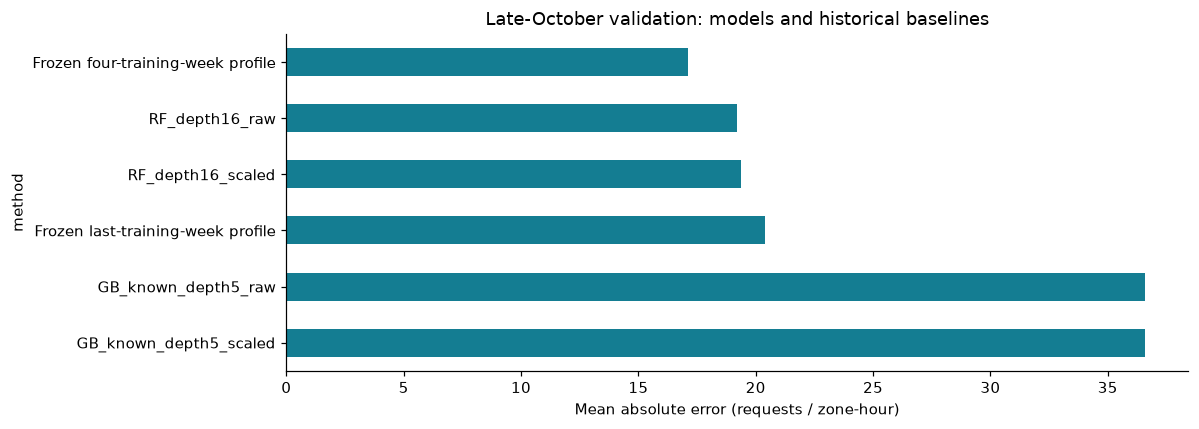

33

In [6]:
calibration_frame = frames['calibrate']
selection_frame = frames['select']
X_calibration = encode_features(encoder, calibration_frame)
X_selection = encode_features(encoder, selection_frame)
y_calibration = calibration_frame['request_count'].to_numpy(dtype=np.float32)
y_selection = selection_frame['request_count'].to_numpy(dtype=np.float32)
scales, validation_predictions, selection_rows = {}, {}, []
for family, name in best_by_family.items():
    model = joblib.load(OUTPUT / f'{name}.joblib')
    calibration_prediction, _ = predict_nonnegative(model, X_calibration)
    scales[name] = count_bias_factor(y_calibration, calibration_prediction)
    raw, _ = predict_nonnegative(model, X_selection)
    validation_predictions[f'{name}_raw'] = raw
    validation_predictions[f'{name}_scaled'] = raw * scales[name]
    del model
    gc.collect()
validation_predictions['Frozen last-training-week profile'] = selection_frame['last_training_week'].to_numpy(dtype=np.float32)
validation_predictions['Frozen four-training-week profile'] = selection_frame['four_training_weeks'].to_numpy(dtype=np.float32)
for name, prediction in validation_predictions.items():
    selection_rows.append({'method': name, **score_counts(y_selection, prediction)})
selection_scores = pd.DataFrame(selection_rows).set_index('method').sort_values(['MAE', 'WAPE_percent'])
winner = selection_scores.reset_index().sort_values(['MAE', 'WAPE_percent', 'method']).iloc[0]['method']
learned_winner = selection_scores.loc[[name for name in selection_scores.index if name.endswith(('_raw', '_scaled'))]].index[0]
display(selection_scores)
print('Count-bias factors fitted on Oct 1–15:', scales)
print('Frozen deployment candidate:', winner, '| best learned model version:', learned_winner)
fig, ax = plt.subplots(figsize=(11, 4))
selection_scores['MAE'].sort_values(ascending=False).plot.barh(ax=ax, color='#147d92')
ax.set(xlabel='Mean absolute error (requests / zone-hour)', title='Late-October validation: models and historical baselines')
plt.tight_layout(); plt.show()
freeze = {'experiment_id': experiment_id, 'experiment': experiment, 'best_by_family': best_by_family,
          'bias_scales': scales, 'selected_method': winner, 'best_learned_method': learned_winner,
          'selection_window': [END_CALIBRATION, END_SELECTION], 'test_window': [END_SELECTION, END_TEST],
          'forecast_protocol': 'Known-ahead calendar/static features only; finalized training profiles frozen before validation',
          'pricing': 'Common base + passenger-mile rate; no time charge; rates undecided',
          'selected_without_test_outcomes_in_this_corrective_run': True, 'test_previously_examined': True, 'pristine_unseen_test': False}
freeze_path = OUTPUT / 'frozen_selection.json'
freeze_path.write_text(json.dumps(freeze, indent=2), encoding='utf-8')
joblib.dump(encoder, OUTPUT / 'zone_encoder.joblib', compress=3)
tuning_scores.to_csv(OUTPUT / 'september_tuning.csv')
selection_scores.to_csv(OUTPUT / 'october_selection.csv')
del X_calibration, X_selection, y_calibration, y_selection, validation_predictions
gc.collect()


## 7. Diagnostic re-evaluation on the previously examined November–December period

The corrected choice is saved before this run reads the period. Its labels were already
seen in the superseded experiment, so these are explicitly diagnostic, not fresh unseen
confirmation. No preceding validation/test request count is used to build any forecast.
Only November–December rows are loaded below to supply scoring labels and schedule fields; the
feature builder takes an explicit calendar/location allowlist and ignores outcomes.
Never retune from these diagnostic scores. Jan 2025 remains drift-only and is not loaded.

In [7]:
assert freeze_path.is_file() and json.loads(freeze_path.read_text())['selected_without_test_outcomes_in_this_corrective_run']
pretest = hours_dataset.to_table(columns=READ_COLUMNS,
    filter=ds.field('period_label') == 'test').to_pandas()
pretest['hour_start_utc'] = pd.to_datetime(pretest['hour_start_utc'], utc=True)
pretest['event_date_nyc'] = pd.to_datetime(pretest['event_date_nyc'])
assert pretest['event_date_nyc'].lt(END_TEST).all()
all_features = attach_frozen_profiles(build_features(pretest, zone_metadata), profiles)
all_features['is_usable'] &= all_features[['last_training_week', 'four_training_weeks']].notna().all(axis=1)
del pretest
gc.collect()
test_mask = period_mask(all_features, END_SELECTION, END_TEST)
test_coverage = {'raw_zone_hours': int(test_mask.sum()),
                 'usable_zone_hours': int((test_mask & all_features['is_usable']).sum()),
                 'missing_targets': int(all_features.loc[test_mask, 'request_count'].isna().sum())}
test_frame = all_features.loc[test_mask & all_features['is_usable']].copy()
del all_features
gc.collect()
X_test = encode_features(encoder, test_frame)
y_test = test_frame['request_count'].to_numpy(dtype=np.float32)
test_predictions = {}
test_negative_counts = {}
for family, name in best_by_family.items():
    model = joblib.load(OUTPUT / f'{name}.joblib')
    raw, negative_count = predict_nonnegative(model, X_test)
    test_predictions[f'{name}_raw'] = raw
    test_predictions[f'{name}_scaled'] = raw * scales[name]
    test_negative_counts[name] = negative_count
    del model
    gc.collect()
test_predictions['Frozen last-training-week profile'] = test_frame['last_training_week'].to_numpy(dtype=np.float32)
test_predictions['Frozen four-training-week profile'] = test_frame['four_training_weeks'].to_numpy(dtype=np.float32)
test_scores = pd.DataFrame({name: score_counts(y_test, prediction) for name, prediction in test_predictions.items()}).T
display(test_scores)
print('Diagnostic scoring coverage:', test_coverage)
print('Negative raw predictions clipped:', test_negative_counts)
print('Method stays fixed from validation:', winner)
test_scores.to_csv(OUTPUT / 'november_december_diagnostic_scores.csv')


Frozen profile join: 385295 -> 385295


,MAE,RMSE,WAPE_percent,mean_bias,rows
GB_known_depth5_raw,39.370759,66.289286,37.385308,-5.683030,384769.0
GB_known_depth5_scaled,39.376247,66.346238,37.390519,-5.879290,384769.0
RF_depth16_raw,23.967918,45.509715,22.759226,-4.068750,384769.0
RF_depth16_scaled,24.198311,45.980337,22.978000,-5.957040,384769.0
Frozen last-training-week profile,25.192113,50.315835,23.921685,-10.850942,384769.0
Frozen four-training-week profile,22.521162,45.071262,21.385429,-10.077979,384769.0


Diagnostic scoring coverage: {'raw_zone_hours': 385295, 'usable_zone_hours': 384769, 'missing_targets': 526}
Negative raw predictions clipped: {'GB_known_depth5': 6935, 'RF_depth16': 0}
Method stays fixed from validation: Frozen four-training-week profile


## 8. Previously examined-period error diagnostics and quieter areas

Compare the already frozen winner with both historical baselines on the same test sample.
Inspect daily city totals and errors by zone group, clock hour and holiday status. Low/high
zone groups are defined from training demand only. These diagnostics describe weaknesses;
they do not become a second chance to select settings on the test set.

No wait time, served share, empty miles or profit result can be inferred from forecast
error alone. A lower MAE does not guarantee better allocation or service fairness.


Daily-total charts leave incomplete dates as gaps rather than draw a false demand collapse.
Metrics still use the declared common usable zone-hour sample, including usable hours on partial dates.

,zone_hours,actual_requests,absolute_errors,MAE,WAPE_percent
training_demand_group,,,,,
Low,96558,1444319.0,468307.50,4.850012,32.424104
Lower-middle,96558,5837769.0,1276842.50,13.223581,21.872097
Upper-middle,95095,10955548.0,2155149.75,22.663124,19.671766
High,96558,22282687.0,4765145.25,49.350082,21.384967


Dates omitted from complete-day total chart: ['2024-11-03']


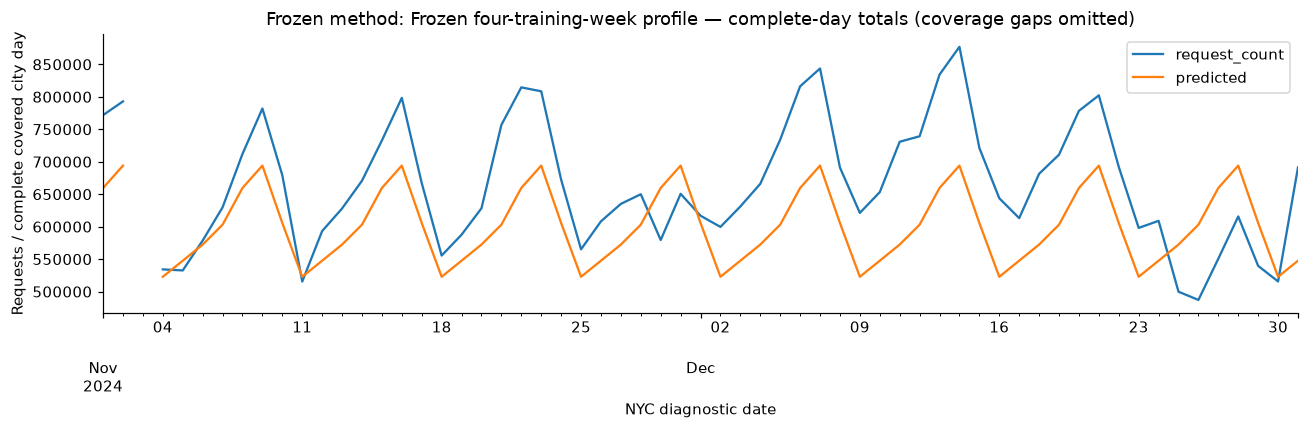

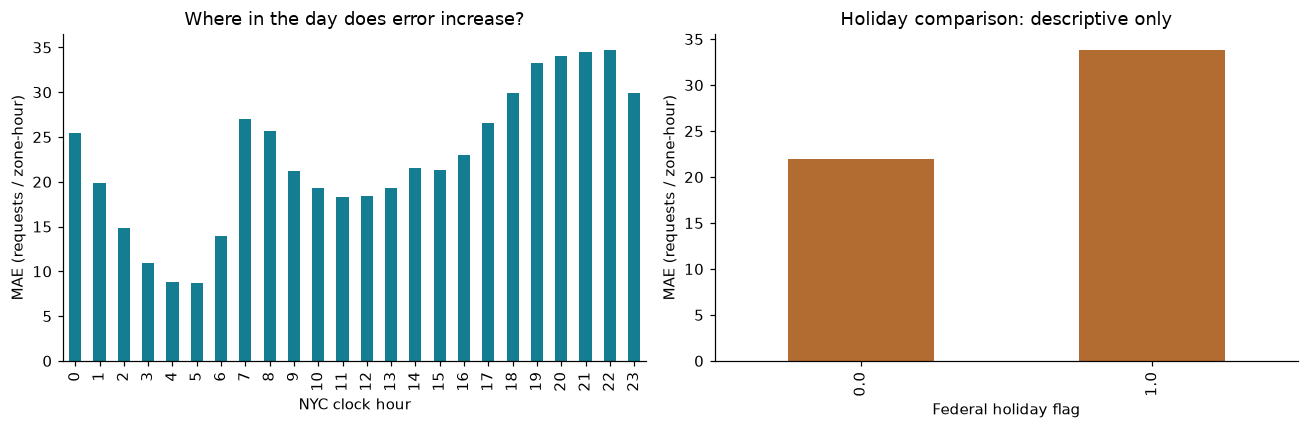

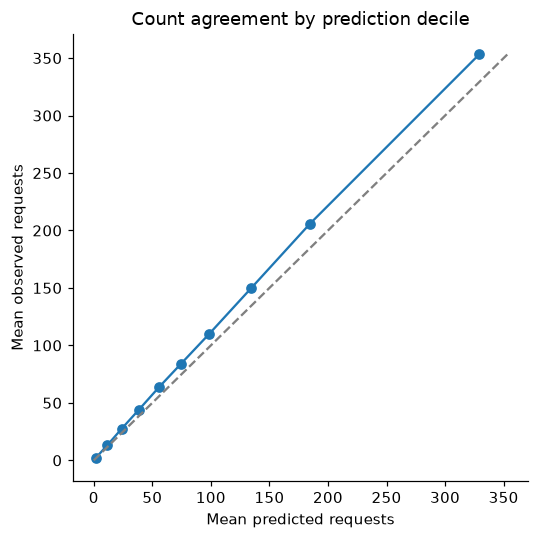

In [8]:
diagnostic = test_frame[['zone_id', 'hour_start_utc', 'event_date_nyc', 'is_federal_holiday', 'request_count']].copy()
diagnostic['predicted'] = test_predictions[winner]
diagnostic['absolute_error'] = np.abs(diagnostic['predicted'] - diagnostic['request_count'])
diagnostic['civil_hour'] = diagnostic['hour_start_utc'].dt.tz_convert('America/New_York').dt.hour
zone_training_rates = frames['train'].groupby('zone_id')['request_count'].mean()
zone_groups = pd.qcut(zone_training_rates.rank(method='first'), 4,
                      labels=['Low', 'Lower-middle', 'Upper-middle', 'High'])
diagnostic['training_demand_group'] = diagnostic['zone_id'].map(zone_groups)
group_scores = diagnostic.groupby('training_demand_group', observed=True).agg(
    zone_hours=('request_count', 'size'), actual_requests=('request_count', 'sum'),
    absolute_errors=('absolute_error', 'sum'), MAE=('absolute_error', 'mean'))
group_scores['WAPE_percent'] = 100 * group_scores['absolute_errors'] / group_scores['actual_requests'].where(group_scores['actual_requests'] > 0)
display(group_scores)
daily_totals = diagnostic.groupby('event_date_nyc')[['request_count', 'predicted']].sum()
daily_rows = diagnostic.groupby('event_date_nyc').size()
expected_daily_rows = pd.Series({day: len(pd.date_range(day.tz_localize('America/New_York'),
    (day + pd.Timedelta(days=1)).tz_localize('America/New_York'), freq='h', inclusive='left')) * len(ZONE_IDS)
    for day in daily_totals.index})
incomplete_dates = daily_rows.ne(expected_daily_rows)
daily_totals.loc[incomplete_dates, :] = np.nan
print('Dates omitted from complete-day total chart:', [str(day.date()) for day in incomplete_dates.index[incomplete_dates]])
daily_totals.plot(figsize=(12, 4), ylabel='Requests / complete covered city day', xlabel='NYC diagnostic date',
                  title=f'Frozen method: {winner} — complete-day totals (coverage gaps omitted)')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
diagnostic.groupby('civil_hour')['absolute_error'].mean().plot.bar(ax=axes[0], color='#147d92')
axes[0].set(xlabel='NYC clock hour', ylabel='MAE (requests / zone-hour)', title='Where in the day does error increase?')
diagnostic.groupby('is_federal_holiday')['absolute_error'].agg(['mean', 'count'])['mean'].plot.bar(ax=axes[1], color='#b26b31')
axes[1].set(xlabel='Federal holiday flag', ylabel='MAE (requests / zone-hour)', title='Holiday comparison: descriptive only')
plt.tight_layout(); plt.show()
bins = pd.qcut(diagnostic['predicted'].rank(method='first'), 10, labels=False)
calibration_plot = diagnostic.groupby(bins)[['request_count', 'predicted']].mean()
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(calibration_plot['predicted'], calibration_plot['request_count'], 'o-')
largest = float(calibration_plot.max().max())
ax.plot([0, largest], [0, largest], '--', color='grey')
ax.set(xlabel='Mean predicted requests', ylabel='Mean observed requests', title='Count agreement by prediction decile')
plt.tight_layout(); plt.show()


## 9. Explain the learned inputs without claiming causation

Training impurity importance measures how much a feature helped split training trees.
We sum borough-indicator columns to show borough identity as one group; coordinates and airport status are separate. This measure can favour
some feature types and spread credit across correlated lag inputs. It is **not SHAP**,
causal influence, or proof that an input will remain useful in deployment. The proposal's
SHAP analysis remains a separate follow-up if required for the final Phase 3 handover.


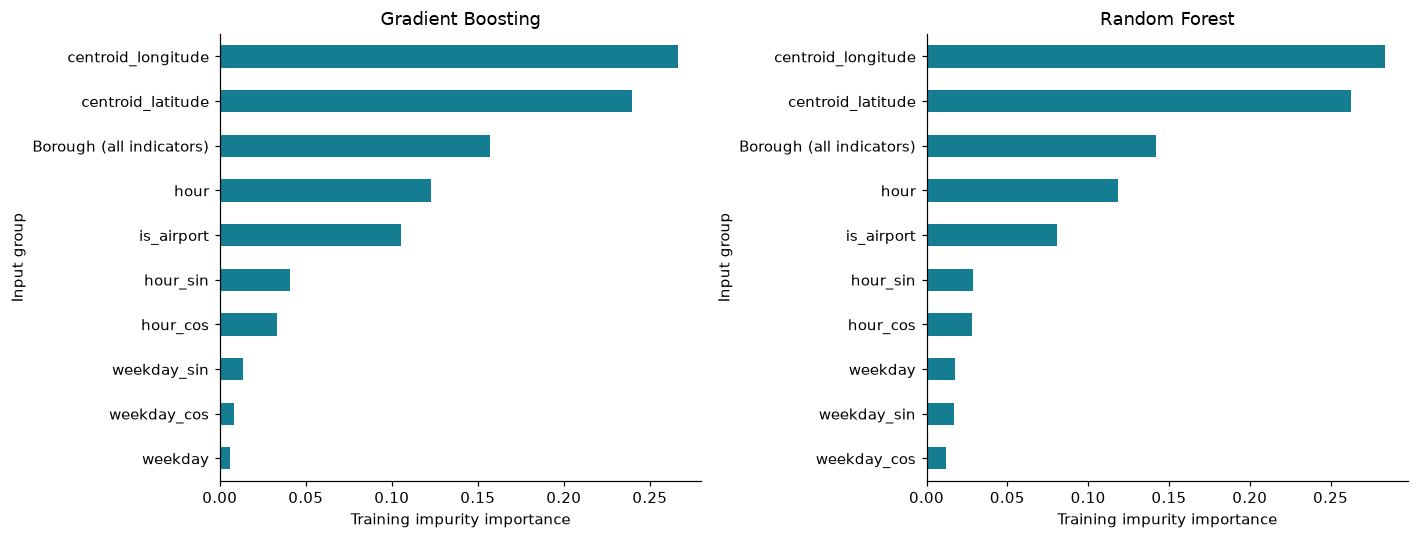

In [9]:
importance_rows = []
for family, name in best_by_family.items():
    model = joblib.load(OUTPUT / f'{name}.joblib')
    importance = model.feature_importances_
    assert len(importance) == len(BOROUGHS) + len(NUMERIC_FEATURES)
    grouped = {'Borough (all indicators)': float(importance[:len(BOROUGHS)].sum())}
    grouped.update({feature: float(value) for feature, value in zip(NUMERIC_FEATURES, importance[len(BOROUGHS):])})
    for feature, value in grouped.items():
        importance_rows.append({'family': family, 'feature': feature, 'importance': value})
    del model
importance_table = pd.DataFrame(importance_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, family in zip(axes, best_by_family):
    importance_table.loc[importance_table['family'] == family].nlargest(10, 'importance').sort_values('importance').plot.barh(
        x='feature', y='importance', ax=ax, legend=False, color='#147d92')
    ax.set(title=family, xlabel='Training impurity importance', ylabel='Input group')
plt.tight_layout(); plt.show()
importance_table.to_csv(OUTPUT / 'training_feature_importance.csv', index=False)


## 10. Demonstrate label-free inference

The following prediction uses only eight schedule rows and static geography. Request
counts and the fixed historical-profile columns are absent. The result must match the
same saved learned model's earlier diagnostic predictions. This is an interface check,
not a new accuracy evaluation or a claim that a live service has been deployed.

In [10]:
schedule_only = test_frame[['zone_id', 'hour_start_utc', 'is_federal_holiday',
                            'has_verified_holiday_calendar']].head(8).copy()
assert 'request_count' not in schedule_only
known_only = build_known_features(schedule_only, zone_metadata)
example_name, example_version = learned_winner.rsplit('_', 1)
example_model = joblib.load(OUTPUT / f'{example_name}.joblib')
example_prediction, _ = predict_nonnegative(example_model, encode_features(encoder, known_only))
if example_version == 'scaled':
    example_prediction *= scales[example_name]
assert np.allclose(example_prediction, test_predictions[learned_winner][:len(schedule_only)], rtol=1e-6, atol=1e-5)
display(schedule_only[['zone_id', 'hour_start_utc']].assign(predicted_requests=example_prediction))
print('PASS: learned-model inference requires no trip/request outcomes.')
del example_model

,zone_id,hour_start_utc,predicted_requests
0,1,2024-11-01 12:00:00+00:00,0.000000
1,1,2024-11-03 00:00:00+00:00,0.001091
2,1,2024-11-03 08:00:00+00:00,5.606431
3,1,2024-11-03 11:00:00+00:00,2.459691
4,1,2024-11-03 20:00:00+00:00,0.003360
5,1,2024-11-04 00:00:00+00:00,0.003360
6,1,2024-11-06 04:00:00+00:00,0.000000
7,1,2024-11-07 17:00:00+00:00,0.000000


PASS: learned-model inference requires no trip/request outcomes.


## 11. Save the corrected artifacts and state what is fixed

Saved models plus encoder require only known calendar and static location fields. Frozen
reference tables require only zone/weekday/hour keys. Neither asks for unfinished trips
or final recent demand. Finalized training data is required once at model-building time;
the offline date split does not establish historical TLC publication timestamps.

Old lag-model results and the conditional 29% improvement are superseded, not reused as
evidence for this corrected contract. Diagnostic scores below may be worse; do not force
a learned model to win. Both RF and GB are saved even if a historical profile wins.

Still outstanding: a prospective untouched evaluation period, SHAP, live deployment,
course/instructor alignment, fixed price rates and fleet-profit simulation. These are
separate tasks; this fix does not claim to resolve them. No profit superiority is tested.

In [11]:
assert all(len(prediction) == len(test_frame) for prediction in test_predictions.values())
assert test_frame['event_date_nyc'].ge(END_SELECTION).all() and test_frame['event_date_nyc'].lt(END_TEST).all()
assert frames['train']['event_date_nyc'].lt(END_TRAIN).all()
assert json.loads(freeze_path.read_text())['selected_method'] == winner
saved_predictions = test_frame[['zone_id', 'hour_start_utc', 'event_date_nyc', 'request_count']].copy()
for name, prediction in test_predictions.items():
    saved_predictions[name] = prediction
saved_predictions.to_parquet(OUTPUT / 'diagnostic_predictions.parquet', index=False)
coverage.to_csv(OUTPUT / 'pretest_coverage.csv')
best_historical_mae = min(test_scores.loc['Frozen last-training-week profile', 'MAE'], test_scores.loc['Frozen four-training-week profile', 'MAE'])
selected_mae = float(test_scores.loc[winner, 'MAE'])
summary = {'created_at_utc': datetime.now(UTC).isoformat(), 'experiment_id': experiment_id,
    'versions': VERSIONS, 'frozen_selection': freeze, 'training_rows': len(frames['train']),
    'test_coverage': test_coverage, 'test_scores': test_scores.reset_index(names='method').to_dict(orient='records'),
    'selected_diagnostic_MAE': selected_mae, 'best_fixed_profile_diagnostic_MAE': float(best_historical_mae),
    'selected_MAE_gain_vs_best_fixed_profile_percent': float(100 * (best_historical_mae - selected_mae) / best_historical_mae),
    'profit_superiority_tested': False, 'test_previously_examined': True, 'pristine_unseen_test': False, 'recent_counts_required_at_inference': False, 'SHAP_complete': False, 'all_cells_reached_final_validation': True}
(OUTPUT / 'forecast_summary.json').write_text(json.dumps(summary, indent=2, allow_nan=False), encoding='utf-8')
display(Markdown(f'**Frozen method:** {winner}. Its diagnostic MAE is **{selected_mae:.2f} requests per zone-hour**. '
                 f'The lower diagnostic MAE of the two historical baselines is **{best_historical_mae:.2f}**. '
                 'The selected method is not changed after seeing these scores. No profit claim is made.'))
print('PASS: known-ahead feature allowlist, diagnostic labels, common comparison rows, finite nonnegative predictions and saved frozen configuration.')
print('Saved local model/forecast directory:', OUTPUT.relative_to(ROOT))


**Frozen method:** Frozen four-training-week profile. Its diagnostic MAE is **22.52 requests per zone-hour**. The lower diagnostic MAE of the two historical baselines is **22.52**. The selected method is not changed after seeing these scores. No profit claim is made.

PASS: known-ahead feature allowlist, diagnostic labels, common comparison rows, finite nonnegative predictions and saved frozen configuration.
Saved local model/forecast directory: data\models\phase3-known-ahead-bac7110ae53581cf
